# Page 13: distilling a GRPO-trained 1.5B into a 0.5B
### Qwen2.5-1.5B-Instruct (GRPO on GSM8K) as teacher, Qwen2.5-0.5B-Instruct as student

| § | Step | Needs the GRPO checkpoint |
|---|---|---|
| 1 | Baselines: the 0.5B student as-is and the untrained 1.5B teacher, on the evaluation sweep | no |
| 1b | Import the GRPO checkpoint: found on Google Drive, or uploaded | it imports it |
| 2 | Traces: each teacher writes 4 chains for 2,000 GSM8K **train** problems; one correct chain per problem is kept | trained teacher only |
| 3 | Fine-tune: one 0.5B student per teacher, plain SFT, loss on the completion only | trained teacher only |
| 4 | Evaluate: both students and the trained teacher, on the same sweep | trained teacher only |
| 5 | Figure and table: majority-vote accuracy against k, mean chain length, a summary table | no |
| 6 | Results file: every number in one JSON | no |

**Controls.** The untrained `Qwen/Qwen2.5-1.5B-Instruct` writes traces the same way as the GRPO checkpoint. The two students differ only in which teacher wrote their data.

**Evaluation sweep.** Identical to the teacher's two-axis run: same chat-template prompt and `#### n` extractor, GSM8K test, n=300 problems, k=32 samples each, temperature 0.7, top-p 0.95, token budgets 64 to 1024, seed 42. Traces use seed 43, on the train split.

**Architecture.** Every generation and training job runs as a subprocess; the kernel only orchestrates and plots. Each stage writes its output to disk, and a stage whose output is already there is skipped.

**The checkpoint.** The GRPO teacher is the two-axis run's `step400` folder: `model.safetensors` (about 3.1 GB, bf16), `config.json` and `generation_config.json`. §1b asks where it is: it searches Google Drive for a `step400` folder, or takes the files as an upload (a Drive download's zips are accepted, and a lone `.safetensors` file gets its config from the base model). If you skip it, the trained-teacher steps print a message and skip, and everything else runs. Once the checkpoint is in place, run all cells again; finished stages are skipped.

> **Run order.** Cell 0.1 installs and then restarts the runtime (Colab reports "Your session crashed"). Afterwards run all cells from the top again; the install cell detects the finished environment and skips.

## 0. Environment

### 0.1 Install (once; restarts the runtime)
vLLM first, so it brings the torch build it was compiled against; then the libraries that don't touch torch. torch is never installed by hand.

In [ ]:
import os, sys, subprocess, importlib.metadata as md
MARKS = ["/content/.distill_env_ok", "/content/.two_axis_env_ok"]   # the second is the two-axis notebook's marker: same environment

def pip(*args):
    print(">", "pip", *args); subprocess.run([sys.executable, "-m", "pip", *args], check=True)

if not any(os.path.exists(m) for m in MARKS):
    pip("install", "-q", "--upgrade", "pip")
    pip("uninstall", "-y", "-q", "torchvision", "torchaudio")        # Colab's copies mismatch vLLM's torch; nothing here needs them
    pip("install", "-q", "--upgrade", "vllm>=0.8.5,<0.33.0")         # brings its own torch + nvidia-* libs
    pip("install", "-q", "--upgrade", "trl>=0.19", "peft", "datasets", "accelerate", "pandas", "matplotlib")
    # self-check in a fresh interpreter; repair a NCCL wheel that does not match torch
    chk = subprocess.run([sys.executable, "-c", "import torch, vllm, trl; print(torch.__version__, vllm.__version__, trl.__version__)"],
                         capture_output=True, text=True)
    if chk.returncode != 0 and "nccl" in chk.stderr.lower():
        need = [r for r in md.requires("torch") if r.startswith("nvidia-nccl")][0].split(";")[0].strip()
        print("repairing NCCL ->", need); pip("install", "-q", "--force-reinstall", "--no-deps", need)
        chk = subprocess.run([sys.executable, "-c", "import torch, vllm, trl"], capture_output=True, text=True)
    if chk.returncode != 0:
        print(chk.stderr[-3000:]); raise SystemExit("environment check failed, see the error above")
    print("versions:", chk.stdout.strip())
    open(MARKS[0], "w").write("ok")
    print("\nEnvironment ready. Restarting the runtime now. Then run all cells from the top.")
    os.kill(os.getpid(), 9)
else:
    print("environment already prepared, skipping install")

environment already prepared, skipping install


### 0.2 Imports and GPU

In [ ]:
import os, sys, json, gc, shlex, subprocess, random, time
from pathlib import Path
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
import trl, vllm, transformers
from IPython.display import display

gpu = torch.cuda.get_device_properties(0); VRAM_GB = round(gpu.total_memory / 2**30)
print(f"GPU: {gpu.name} | VRAM {VRAM_GB} GB | torch {torch.__version__} cu{torch.version.cuda} | vllm {vllm.__version__} | trl {trl.__version__} | transformers {transformers.__version__}")
assert torch.cuda.is_available()
# optional: from google.colab import userdata; os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


GPU: NVIDIA A100-SXM4-80GB | VRAM 79 GB | torch 2.13.0+cu130 cu13.0 | vllm 0.32.0 | trl 1.17.1 | transformers 5.19.0


### 0.3 Knobs, the only cell you edit
`TEACHER_PATH` is the GRPO checkpoint: a Hugging Face folder (full fine-tune) or a LoRA adapter, which is merged before use. Left empty, §1b imports the checkpoint into `TEACHER_DIR`. The evaluation settings match the teacher's two-axis run.

In [ ]:
MOUNT_DRIVE  = True             # True -> results under /content/drive/MyDrive/distill_0p5b (survives disconnects)
RESULTS_ROOT = "/content/drive/MyDrive/distill_0p5b" if MOUNT_DRIVE else "/content/distill_0p5b"

# Pointing directly to the folder in your Google Drive
TEACHER_PATH = "/content/drive/MyDrive/Sapiotomy_Final_Notebook_Set"
TEACHER_DIR  = "/content/teacher_step400"      # where %1b puts the imported checkpoint (local disk)
TEACHER_BASE = "Qwen/Qwen2.5-1.5B-Instruct"    # the untrained control teacher, and the GRPO run's starting point
STUDENT_ID   = "Qwen/Qwen2.5-0.5B-Instruct"

N_PROB       = 2000              # GSM8K train problems each teacher writes traces for
PER          = 4                 # chains per problem
TRACE_SEED   = 43                # draws the train problems and seeds trace sampling

SEED         = 42                # evaluation seed, as in the teacher's run
N_EVAL       = 300               # GSM8K test problems
K_MAX        = 32                # samples per test problem
TEMPERATURE  = 0.7               # top-p 0.95 is fixed in eval_ckpt.py
BUDGETS      = [64, 128, 256, 512, 1024]
MAX_TOKENS   = max(BUDGETS)      # generation cap for evaluation and for traces
MAX_PROMPT   = 256

SFT_EPOCHS   = 2
SFT_LR       = 1e-5
GPU_UTIL     = 0.85

if MOUNT_DRIVE:
    from google.colab import drive; drive.mount("/content/drive")
for d in ["eval", "data", "ckpt"]:
    Path(f"{RESULTS_ROOT}/{d}").mkdir(parents=True, exist_ok=True)
SETTINGS = dict(teacher_path=TEACHER_PATH, teacher_base=TEACHER_BASE, student_id=STUDENT_ID,
                n_prob=N_PROB, per=PER, trace_seed=TRACE_SEED, seed=SEED, n_eval=N_EVAL, k_max=K_MAX,
                temperature=TEMPERATURE, top_p=0.95, budgets=BUDGETS, max_tokens=MAX_TOKENS, max_prompt=MAX_PROMPT,
                sft_epochs=SFT_EPOCHS, sft_lr=SFT_LR, gpu=gpu.name)
json.dump(SETTINGS, open(f"{RESULTS_ROOT}/settings.json", "w"), indent=2)

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed); transformers.set_seed(seed)
seed_everything(SEED)
if not TEACHER_PATH and (Path(TEACHER_DIR) / "config.json").exists():
    TEACHER_PATH = TEACHER_DIR      # imported earlier in this runtime
print(f"results -> {RESULTS_ROOT}\nteacher -> {TEACHER_PATH or '(not set: %1b imports it)'}")

Mounted at /content/drive
results -> /content/drive/MyDrive/distill_0p5b
teacher -> (not set: §1b imports it)


### 0.4 Shared module and worker scripts
`common.py` is the two-axis notebook's module (prompt, extractor, loader, majority vote) plus the trace filter. `eval_ckpt.py` is its evaluation worker, unchanged. `distill_sft.py` is its SFT worker, set to prompt/completion rows with loss on the completion only.

In [ ]:
%%writefile common.py
import re, json
from collections import Counter
from datasets import load_dataset

SYSTEM = "Think step by step. Then give the final answer on its own line as: #### <number>"
NUM = r"-?\$?\d[\d,]*\.?\d*"

def normalize(s):
    if s is None: return None
    s = s.replace(",", "").replace("$", "").strip().rstrip(".")
    try:
        f = float(s); return str(int(f)) if f == int(f) else str(f)
    except ValueError:
        return None

def extract(text):
    """Last '#### n' if present, else the last number in the text (what a truncated trace yields)."""
    m = re.findall(r"####\s*(" + NUM + ")", text)
    if m: return normalize(m[-1])
    nums = re.findall(NUM, text)
    return normalize(nums[-1]) if nums else None

def gold(answer_field): return normalize(answer_field.split("####")[-1])

def to_prompt(ex):
    return {"prompt": [{"role": "system", "content": SYSTEM}, {"role": "user", "content": ex["question"]}],
            "answer": gold(ex["answer"])}

def load_gsm8k(split, n=None, seed=0):
    ds = load_dataset("openai/gsm8k", "main", split=split).map(to_prompt).shuffle(seed=seed)
    return ds.select(range(n)) if n else ds

def maj(answers):
    c = Counter(a for a in answers if a is not None)
    return c.most_common(1)[0][0] if c else None

def ks_up_to(k_max):
    ks, k = [], 1
    while k <= k_max: ks.append(k); k *= 2
    return ks

def make_config(cls, **kw):
    """Build a TrainingArguments-derived config, dropping kwargs the installed transformers/trl does not accept; prints what it dropped."""
    import dataclasses
    valid = {f.name for f in dataclasses.fields(cls)}
    dropped = {k: v for k, v in kw.items() if k not in valid}
    if dropped: print(f"[compat] {cls.__name__} does not accept {dropped} in this version - dropped", flush=True)
    return cls(**{k: v for k, v in kw.items() if k in valid})

# ---- checkpoint check ----
def safetensors_summary(path):
    """Read a .safetensors header without loading weights: tensor count, parameter count, dtypes,
    the embedding shape, LoRA keys, and whether the file is as long as its header says (a cut-off upload is not)."""
    import os, struct, math
    with open(path, "rb") as f:
        n = struct.unpack("<Q", f.read(8))[0]; h = json.loads(f.read(n))
    h.pop("__metadata__", None)
    end = max(v["data_offsets"][1] for v in h.values())
    return {"tensors": len(h), "params": sum(math.prod(v["shape"]) for v in h.values()),
            "dtypes": sorted({v["dtype"] for v in h.values()}),
            "embed_shape": h.get("model.embed_tokens.weight", {}).get("shape"),
            "lora": any("lora_" in k for k in h), "complete": os.path.getsize(path) == 8 + n + end}

def check_teacher_weights(path, embed_shape=(151936, 1536), params=(1.4e9, 1.7e9)):
    """Raise unless the file is a complete, merged Qwen2.5-1.5B checkpoint."""
    s = safetensors_summary(path)
    problems = [msg for bad, msg in [
        (not s["complete"], "file is shorter than its header says (incomplete download or upload)"),
        (s["lora"], "holds LoRA adapter weights, not a merged model"),
        (tuple(s["embed_shape"] or ()) != tuple(embed_shape), f"embedding shape {s['embed_shape']}, expected {list(embed_shape)}"),
        (not params[0] <= s["params"] <= params[1], f"{s['params'] / 1e9:.2f}B parameters, expected about 1.5B")] if bad]
    if problems: raise ValueError(f"{path}: " + "; ".join(problems))
    return s

# ---- trace filter ----
def has_final(text):
    return re.search(r"####\s*" + NUM, text) is not None

def usable(ans, text, n_tokens, gold_ans, max_tokens):
    """A kept chain is correct, writes its own '#### n' line, and stopped before the token cap."""
    return ans is not None and ans == gold_ans and has_final(text) and n_tokens < max_tokens

def build_sft_rows(prompts, per, max_tokens):
    """One prompt/completion row per problem from its first usable chain, plus coverage counts.
    prompts: chat prompts in the same order as per; per: the eval worker's saved texts."""
    assert len(prompts) == len(per), (len(prompts), len(per))
    rows, any_right = [], 0
    for prompt, x in zip(prompts, per):
        any_right += any(a is not None and a == x["gold"] for a in x["answers"])
        for a, t, n in zip(x["answers"], x["texts"], x["lens"]):
            if usable(a, t, n, x["gold"], max_tokens):
                rows.append({"prompt": prompt, "completion": [{"role": "assistant", "content": t.strip()}]}); break
    stats = {"problems": len(per), "chains_per_problem": len(per[0]["answers"]) if per else 0,
             "any_correct": any_right, "kept": len(rows)}
    return rows, stats

Writing common.py


In [ ]:
%%writefile eval_ckpt.py
# worker: one vLLM pass -> k samples per problem -> maj@k, pass@k, truncated-budget accuracy, lengths.
import argparse, json, time
from pathlib import Path
from vllm import LLM, SamplingParams
from common import load_gsm8k, extract, maj, ks_up_to
p = argparse.ArgumentParser()
for f in ["--model", "--tokenizer", "--out", "--tag", "--budgets"]: p.add_argument(f, required=True)
p.add_argument("--split", default="test"); p.add_argument("--n", type=int, required=True); p.add_argument("--k", type=int, required=True)
p.add_argument("--max_tokens", type=int, required=True); p.add_argument("--temperature", type=float, default=0.7)
p.add_argument("--seed", type=int, default=42); p.add_argument("--gpu_util", type=float, default=0.85); p.add_argument("--save_texts", action="store_true")
a = p.parse_args(); t0 = time.time()
ds = load_gsm8k(a.split, n=a.n, seed=a.seed)
llm = LLM(model=a.model, tokenizer=a.tokenizer, dtype="bfloat16", seed=a.seed, gpu_memory_utilization=a.gpu_util,
          max_model_len=512 + a.max_tokens, enable_prefix_caching=True)
tok = llm.get_tokenizer()
prompts = [tok.apply_chat_template(ex["prompt"], tokenize=False, add_generation_prompt=True) for ex in ds]
golds = [ex["answer"] for ex in ds]
outs = llm.generate(prompts, SamplingParams(n=a.k, temperature=a.temperature, top_p=0.95, max_tokens=a.max_tokens, seed=a.seed))
budgets = [int(b) for b in a.budgets.split(",")]; ks = ks_up_to(a.k)
per = []; lens = []; trunc = 0
for out, g in zip(outs, golds):
    ss = out.outputs; lens += [len(s.token_ids) for s in ss]; trunc += sum(len(s.token_ids) >= a.max_tokens for s in ss)
    per.append({"gold": g, "answers": [extract(s.text) for s in ss], "lens": [len(s.token_ids) for s in ss],
                "seq": {b: extract(tok.decode(ss[0].token_ids[:b])) for b in budgets},
                "texts": [s.text for s in ss] if a.save_texts else None})
res = {"tag": a.tag, "model": a.model, "n": len(golds), "k_max": a.k, "max_tokens": a.max_tokens,
       "maj_at_k": {k: sum(maj(x["answers"][:k]) == x["gold"] for x in per) / len(per) for k in ks},
       "pass_at_k": {k: sum(any(y == x["gold"] for y in x["answers"][:k]) for x in per) / len(per) for k in ks},
       "seq_at_budget": {b: sum(x["seq"][b] == x["gold"] for x in per) / len(per) for b in budgets},
       "mean_len": sum(lens) / len(lens), "frac_truncated": trunc / len(lens), "seconds": round(time.time() - t0, 1)}
Path(a.out).parent.mkdir(parents=True, exist_ok=True)
if a.save_texts:
    for x in per: x.pop("seq")
    json.dump(per, open(a.out.replace(".json", "_texts.json"), "w"))
json.dump(res, open(a.out, "w"), indent=1)   # written last: its presence marks the stage done
print(json.dumps({k: v for k, v in res.items() if k in ("tag", "n", "mean_len", "frac_truncated", "seconds")}))
print("maj@k", res["maj_at_k"]); print("seq@budget", res["seq_at_budget"])

Writing eval_ckpt.py


In [ ]:
%%writefile distill_sft.py
# worker: plain SFT on prompt/completion rows, loss on the completion only.
import argparse, json
from pathlib import Path
from datasets import Dataset
from trl import SFTConfig, SFTTrainer
from transformers import set_seed
from common import make_config
p = argparse.ArgumentParser(); p.add_argument("--data", required=True); p.add_argument("--student", required=True); p.add_argument("--out", required=True)
p.add_argument("--seed", type=int, default=42); p.add_argument("--max_len", type=int, default=1280)
p.add_argument("--epochs", type=int, default=2); p.add_argument("--lr", type=float, default=1e-5); a = p.parse_args()
set_seed(a.seed); ds = Dataset.from_list(json.load(open(a.data))).shuffle(seed=a.seed)
steps = a.epochs * -(-len(ds) // 16)   # effective batch 16
args = make_config(SFTConfig, output_dir=a.out + "_trainer", seed=a.seed, num_train_epochs=a.epochs, learning_rate=a.lr,
                   per_device_train_batch_size=8, gradient_accumulation_steps=2, max_length=a.max_len, completion_only_loss=True,
                   bf16=True, gradient_checkpointing=True, logging_steps=10, save_strategy="no", report_to="none",
                   lr_scheduler_type="cosine", warmup_steps=max(1, int(0.05 * steps)), model_init_kwargs={"dtype": "bfloat16"})
assert getattr(args, "completion_only_loss", None) is True, "this TRL version has no completion_only_loss"
t = SFTTrainer(model=a.student, args=args, train_dataset=ds); t.train()
t.model.save_pretrained(a.out); t.processing_class.save_pretrained(a.out)
json.dump(t.state.log_history, open(f"{a.out}/log_history.json", "w"))
json.dump({"rows": len(ds), "steps": t.state.global_step}, open(f"{a.out}/sft_done.json", "w"))   # written last: marks the stage done
print("distill done")

Writing distill_sft.py


### 0.5 Orchestration helpers

In [ ]:
def run(cmd, log_path=None):
    # stream a worker's output into the notebook (and optionally a log file); raise on failure
    print(">", cmd, flush=True)
    proc = subprocess.Popen(shlex.split(cmd), stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    tail, f = [], (open(log_path, "a") if log_path else None)
    for line in proc.stdout:
        tail.append(line); tail = tail[-60:]
        if f: f.write(line)
        if any(t in line for t in ("loss", "it/s", "s/it", "done", "Error", "error", "maj@k", "seq@")):
            print(line.rstrip()[-200:], flush=True)
    proc.wait()
    if f: f.close()
    if proc.returncode != 0:
        print("".join(tail)); raise RuntimeError(f"worker failed (exit {proc.returncode}): {cmd.split()[1]}")

def teacher_ready():
    if not TEACHER_PATH: return False
    p = Path(TEACHER_PATH)
    return (p / "config.json").exists() or (p / "adapter_config.json").exists()

def skip_msg(step):
    print(f"[skip] {step}: no GRPO checkpoint yet (TEACHER_PATH = {TEACHER_PATH!r}). "
          f"Import it in §1b, or set TEACHER_PATH in 0.3, and run the cells again.")

def materialize(path, base_id):
    # path vLLM and TRL can load: the folder itself for a full fine-tune; merged weights for a LoRA adapter
    if (Path(path) / "adapter_config.json").exists():
        merged = path.rstrip("/") + "-merged"
        if not (Path(merged) / "config.json").exists():
            from transformers import AutoModelForCausalLM, AutoTokenizer
            from peft import PeftModel
            base = AutoModelForCausalLM.from_pretrained(base_id, dtype=torch.bfloat16, device_map="cuda")
            m = PeftModel.from_pretrained(base, path).merge_and_unload()
            m.save_pretrained(merged, safe_serialization=True); AutoTokenizer.from_pretrained(base_id).save_pretrained(merged)
            del m, base; gc.collect(); torch.cuda.empty_cache()
        return merged
    return path

def teacher_model(name):
    # vLLM path for a teacher arm, or None when the trained checkpoint is missing
    if name == "untrained": return TEACHER_BASE
    return materialize(TEACHER_PATH, TEACHER_BASE) if teacher_ready() else None

def eval_path(tag): return f"{RESULTS_ROOT}/eval/{tag}.json"

def run_eval(model_path, tokenizer, tag, split="test", n=N_EVAL, k=K_MAX, seed=SEED, save_texts=False):
    out = eval_path(tag)
    done = Path(out).exists() and (not save_texts or Path(out.replace(".json", "_texts.json")).exists())
    if done:
        print(f"[cached] {out}")
    else:
        run(f"{sys.executable} eval_ckpt.py --model {model_path} --tokenizer {tokenizer} --out {out} --tag {tag} --split {split} "
            f"--n {n} --k {k} --max_tokens {MAX_TOKENS} --budgets {','.join(map(str, BUDGETS))} "
            f"--temperature {TEMPERATURE} --seed {seed} --gpu_util {GPU_UTIL} {'--save_texts' if save_texts else ''}",
            log_path=out.replace(".json", ".log"))
    return json.load(open(out))

def load_eval(tag):
    p = Path(eval_path(tag)); return json.load(open(p)) if p.exists() else None

# JSON turns int keys into strings; these accessors accept either
getk = lambda r, k: r["maj_at_k"].get(str(k), r["maj_at_k"].get(k))
getp = lambda r, k: r["pass_at_k"].get(str(k), r["pass_at_k"].get(k))

from common import ks_up_to, extract, load_gsm8k, build_sft_rows
for t, w in {"so the answer is #### 1,250": "1250", "#### $18.00": "18", "total = 42 so": "42", "none": None, "#### 3\nwait #### 5": "5"}.items():
    assert extract(t) == w, (t, extract(t), w)
print("helpers ready; extractor OK |", "GRPO checkpoint found" if teacher_ready() else "GRPO checkpoint NOT found yet")

helpers ready; extractor OK | GRPO checkpoint NOT found yet


## 1. Baselines
The 0.5B student as-is and the untrained 1.5B teacher, on the evaluation sweep. Neither needs the GRPO checkpoint.

In [ ]:
run_eval(STUDENT_ID, STUDENT_ID, tag="student_base")
run_eval(TEACHER_BASE, TEACHER_BASE, tag="teacher_untrained")
for tag in ["student_base", "teacher_untrained"]:
    r = load_eval(tag); print(f"{tag:>18}: one sample {getk(r, 1):.1%} | maj@{K_MAX} {getk(r, K_MAX):.1%} | mean length {r['mean_len']:.0f} tokens")

> /usr/bin/python3 eval_ckpt.py --model Qwen/Qwen2.5-0.5B-Instruct --tokenizer Qwen/Qwen2.5-0.5B-Instruct --out /content/drive/MyDrive/distill_0p5b/eval/student_base.json --tag student_base --split test --n 300 --k 32 --max_tokens 1024 --budgets 64,128,256,512,1024 --temperature 0.7 --seed 42 --gpu_util 0.85 
Fetching 9 files: 100%|██████████| 9/9 [00:00<00:00, 42.37it/s]
Loading safetensors checkpoint shards:   0% Completed | 0/1 [00:00<?, ?it/s]
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  3.06it/s]
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  3.06it/s]
Processed prompts: 100%|██████████| 9600/9600 [01:47<00:00, 89.59it/s, est. speed input: 8451.13 toks/s, output: 17122.29 toks/s]
maj@k {1: 0.2833333333333333, 2: 0.2833333333333333, 4: 0.38333333333333336, 8: 0.46, 16: 0.5166666666666667, 32: 0.5433333333333333}
seq@budget {64: 0.06666666666666667, 128: 0.09666666666666666, 256: 0.22333333333333333, 512: 0.2833333333333333, 

## 1b. Import the GRPO checkpoint
Asks where the step-400 checkpoint is: **[d]** search Google Drive for a `step400` folder, **[u]** upload the files from this computer, **[s]** skip for now. Upload takes `model.safetensors` (any name ending in `.safetensors`), `config.json` and `generation_config.json`, or the zips Google Drive makes when it downloads the folder; whatever config is missing is copied from `Qwen/Qwen2.5-1.5B-Instruct`, whose architecture is identical. The weights are checked before use: a complete file, no LoRA keys, Qwen2.5-1.5B's shapes. Skipped when the checkpoint is already in place.

In [ ]:
import glob, shutil, zipfile
from common import check_teacher_weights

def assemble(files, dest=TEACHER_DIR):
    """Build a loadable HF folder in dest from uploaded or found files (.safetensors, configs, zips of either)."""
    tmp = Path(dest + "_incoming"); shutil.rmtree(tmp, ignore_errors=True); tmp.mkdir(parents=True)
    for f in files:
        if str(f).endswith(".zip"):
            with zipfile.ZipFile(f) as z:
                for m in z.namelist():
                    if m.endswith((".safetensors", ".json")) and not m.endswith("/"):
                        with z.open(m) as src, open(tmp / Path(m).name, "wb") as dst: shutil.copyfileobj(src, dst, 1 << 24)
        else:
            shutil.copy(f, tmp / Path(f).name)
    weights = sorted(tmp.glob("*.safetensors"))
    if not weights: raise FileNotFoundError("no .safetensors file among " + ", ".join(Path(f).name for f in files))
    if len(weights) == 1 and weights[0].name != "model.safetensors":
        weights[0].rename(tmp / "model.safetensors")    # Drive renames downloads, e.g. model-001.safetensors
    elif len(weights) > 1 and not (tmp / "model.safetensors.index.json").exists():
        raise ValueError(f"{len(weights)} weight files and no model.safetensors.index.json: upload one checkpoint at a time")
    for w in sorted(tmp.glob("*.safetensors")):
        s = check_teacher_weights(str(w))
        if len(weights) == 1: print(f"weights OK: {s['tensors']} tensors, {s['params'] / 1e9:.2f}B parameters, {s['dtypes']}")
    for name in ["config.json", "generation_config.json"]:
        if not (tmp / name).exists():
            from huggingface_hub import hf_hub_download
            shutil.copy(hf_hub_download(TEACHER_BASE, name), tmp / name); print(f"{name}: copied from {TEACHER_BASE}")
    shutil.rmtree(dest, ignore_errors=True); tmp.rename(dest)
    return dest

if teacher_ready():
    print(f"GRPO checkpoint in place: {TEACHER_PATH}")
else:
    target_folder = "/content/drive/MyDrive/Sapiotomy_Final_Notebook_Set"
    if not Path("/content/drive").exists():
        from google.colab import drive; drive.mount("/content/drive")

    if Path(target_folder).exists():
        print(f"Found folder: {target_folder}. Assembling files...")
        files = [str(p) for p in Path(target_folder).iterdir() if p.suffix in (".safetensors", ".json") or p.name == "step_400_model.safetensors"]
        TEACHER_PATH = assemble(files)
    else:
        raise FileNotFoundError(f"Could not find the folder at {target_folder}")

    if teacher_ready():
        print(f"GRPO checkpoint ready: {TEACHER_PATH}")

Found folder: /content/drive/MyDrive/Sapiotomy_Final_Notebook_Set. Assembling files...
weights OK: 338 tensors, 1.54B parameters, ['BF16']


config.json: copied from Qwen/Qwen2.5-1.5B-Instruct
generation_config.json: copied from Qwen/Qwen2.5-1.5B-Instruct
GRPO checkpoint ready: /content/teacher_step400


## 2. Traces
Each teacher writes `PER` chains for each of `N_PROB` GSM8K train problems, drawn and sampled with `TRACE_SEED`. A kept chain is correct, writes its own `#### n` line, and stopped before the token cap; the first such chain per problem becomes one training row. Coverage counts the problems where at least one chain was right.

In [ ]:
def write_traces(name):
    data_path, stats_path = f"{RESULTS_ROOT}/data/{name}.json", f"{RESULTS_ROOT}/data/{name}_stats.json"
    if Path(stats_path).exists():
        print(f"[cached] {data_path}"); return json.load(open(stats_path))
    model = teacher_model(name)
    if model is None: skip_msg(f"traces from the {name} teacher"); return None
    run_eval(model, TEACHER_BASE, tag=f"traces_{name}", split="train", n=N_PROB, k=PER, seed=TRACE_SEED, save_texts=True)
    per = json.load(open(eval_path(f"traces_{name}").replace(".json", "_texts.json")))
    src = load_gsm8k("train", n=N_PROB, seed=TRACE_SEED)
    assert [ex["answer"] for ex in src] == [x["gold"] for x in per], "trace file and problem draw disagree"
    rows, stats = build_sft_rows([ex["prompt"] for ex in src], per, MAX_TOKENS)
    json.dump(rows, open(data_path, "w")); json.dump(stats, open(stats_path, "w"), indent=1)   # stats last: marks the stage done
    return stats

COVERAGE = {}
for name in ["untrained", "trained"]:
    s = write_traces(name)
    if s:
        COVERAGE[name] = s
        print(f"{name:>9} teacher: {s['any_correct']}/{s['problems']} problems with at least one right chain of {s['chains_per_problem']} "
              f"({s['any_correct'] / s['problems']:.1%}) | {s['kept']} rows kept")

[cached] /content/drive/MyDrive/distill_0p5b/data/untrained.json
untrained teacher: 1851/2000 problems with at least one right chain of 4 (92.5%) | 896 rows kept
[cached] /content/drive/MyDrive/distill_0p5b/data/trained.json
  trained teacher: 1893/2000 problems with at least one right chain of 4 (94.7%) | 1891 rows kept


## 3. Fine-tune two students
One 0.5B student per teacher, from the same `STUDENT_ID`, with the same settings: plain SFT on the prompt/completion rows, loss on the completion only, `SFT_EPOCHS` epochs, effective batch 16, learning rate `SFT_LR`, cosine schedule.

In [ ]:
def student_path(name): return f"{RESULTS_ROOT}/ckpt/student_from_{name}"

def train_student(name):
    out, data = student_path(name), f"{RESULTS_ROOT}/data/{name}.json"
    if (Path(out) / "sft_done.json").exists():
        print(f"[cached] {out}"); return True
    if not Path(f"{RESULTS_ROOT}/data/{name}_stats.json").exists():
        skip_msg(f"SFT on the {name} teacher's traces"); return False
    t0 = time.time()
    run(f"{sys.executable} distill_sft.py --data {data} --student {STUDENT_ID} --out {out} --seed {SEED} "
        f"--max_len {MAX_PROMPT + MAX_TOKENS} --epochs {SFT_EPOCHS} --lr {SFT_LR}", log_path=f"{out}.log")
    print(f"student_from_{name}: {(time.time() - t0) / 60:.1f} min"); return True

for name in ["untrained", "trained"]:
    train_student(name)

[cached] /content/drive/MyDrive/distill_0p5b/ckpt/student_from_untrained
[cached] /content/drive/MyDrive/distill_0p5b/ckpt/student_from_trained


## 4. Evaluate
Both students and the GRPO teacher, on the evaluation sweep from §1.

In [21]:
def student_path(name): return f"{RESULTS_ROOT}/ckpt/student_from_{name}"

for name in ["untrained", "trained"]:
    if (Path(student_path(name)) / "sft_done.json").exists():
        run_eval(student_path(name), STUDENT_ID, tag=f"student_from_{name}")
    else:
        skip_msg(f"evaluating student_from_{name}")
if teacher_ready():
    run_eval(teacher_model("trained"), TEACHER_BASE, tag="teacher_trained")
else:
    skip_msg("evaluating the GRPO teacher")

> /usr/bin/python3 eval_ckpt.py --model /content/drive/MyDrive/distill_0p5b/ckpt/student_from_untrained --tokenizer Qwen/Qwen2.5-0.5B-Instruct --out /content/drive/MyDrive/distill_0p5b/eval/student_from_untrained.json --tag student_from_untrained --split test --n 300 --k 32 --max_tokens 1024 --budgets 64,128,256,512,1024 --temperature 0.7 --seed 42 --gpu_util 0.85 
Fetching 9 files: 100%|██████████| 9/9 [00:00<00:00, 1622.90it/s]
Loading safetensors checkpoint shards:   0% Completed | 0/1 [00:00<?, ?it/s]
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  1.45it/s]
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  1.45it/s]
Processed prompts: 100%|██████████| 9600/9600 [01:50<00:00, 86.76it/s, est. speed input: 8184.81 toks/s, output: 15950.55 toks/s]
maj@k {1: 0.42333333333333334, 2: 0.42333333333333334, 4: 0.5166666666666667, 8: 0.5733333333333334, 16: 0.62, 32: 0.6266666666666667}
seq@budget {64: 0.08666666666666667, 128: 0.22, 256: 0

## 5. Figure and table
**Left:** majority-vote accuracy against the number of samples k, log scale; 0.5B models solid, 1.5B teachers dashed, each student in its teacher's colour. **Right:** mean chain length on the test sweep. Below: one sample, majority of 32, any of 32 right, and mean length per model. Models not yet evaluated are left out.

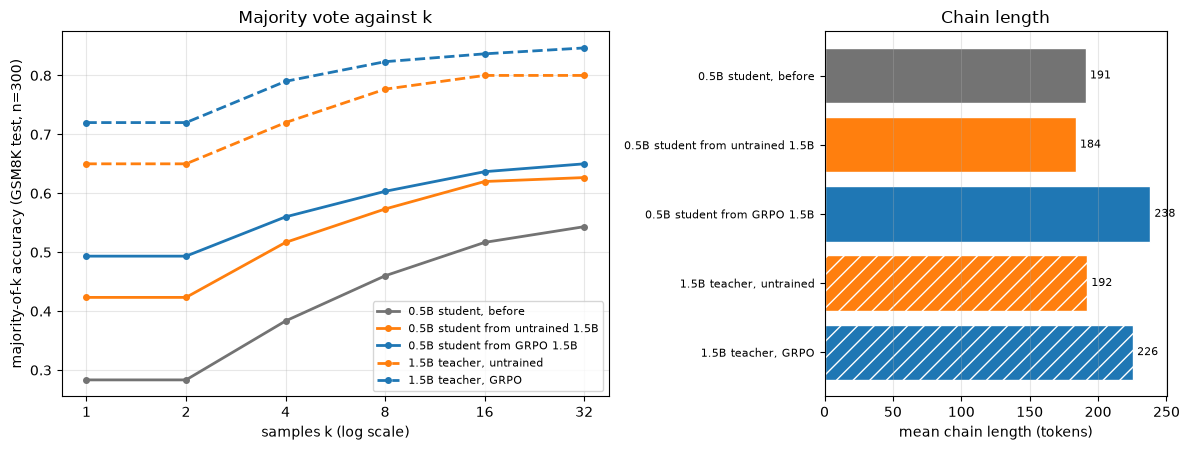

,one sample,majority of 32,any of 32 right,mean length (tokens)
model,,,,
"0.5B student, before",28.3%,54.3%,88.7%,191
0.5B student from untrained 1.5B,42.3%,62.7%,88.7%,184
0.5B student from GRPO 1.5B,49.3%,65.0%,90.0%,238
"1.5B teacher, untrained",65.0%,80.0%,95.7%,192
"1.5B teacher, GRPO",72.0%,84.7%,97.3%,226


student from GRPO teacher minus student from untrained teacher: one sample +7.0% | majority of 32 +2.3% (one standard error per model is about 2.9% at n=300)


In [22]:
MODELS = [  # tag, label, size, colour
    ("student_base",           "0.5B student, before",              "0.5B", "0.45"),
    ("student_from_untrained", "0.5B student from untrained 1.5B",  "0.5B", "tab:orange"),
    ("student_from_trained",   "0.5B student from GRPO 1.5B",       "0.5B", "tab:blue"),
    ("teacher_untrained",      "1.5B teacher, untrained",           "1.5B", "tab:orange"),
    ("teacher_trained",        "1.5B teacher, GRPO",                "1.5B", "tab:blue"),
]
RES = {tag: load_eval(tag) for tag, *_ in MODELS}
present = [m for m in MODELS if RES[m[0]] is not None]
ks = ks_up_to(K_MAX)

fig, (ax, bx) = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1.6, 1]})
for tag, lab, size, col in present:
    ax.plot(ks, [getk(RES[tag], k) for k in ks], "o-" if size == "0.5B" else "o--", color=col, label=lab, lw=2, ms=4)
ax.set_xscale("log", base=2); ax.set_xticks(ks); ax.set_xticklabels(ks); ax.grid(alpha=.3); ax.legend(fontsize=8, loc="best")
ax.set(xlabel="samples k (log scale)", ylabel=f"majority-of-k accuracy (GSM8K test, n={N_EVAL})", title="Majority vote against k")
y = np.arange(len(present))
bx.barh(y, [RES[t]["mean_len"] for t, *_ in present], color=[c for *_, c in present], edgecolor="white")
for i, (tag, lab, size, col) in enumerate(present):
    if size == "1.5B": bx.patches[i].set_hatch("//")
    bx.text(RES[tag]["mean_len"], i, f" {RES[tag]['mean_len']:.0f}", va="center", fontsize=8)
bx.set_yticks(y); bx.set_yticklabels([lab for _, lab, *_ in present], fontsize=8); bx.invert_yaxis()
bx.set(xlabel="mean chain length (tokens)", title="Chain length"); bx.grid(axis="x", alpha=.3)
plt.tight_layout(); plt.savefig(f"{RESULTS_ROOT}/fig_distill.png", dpi=130); plt.show()

TABLE = pd.DataFrame([{"model": lab, "one sample": getk(RES[t], 1), f"majority of {K_MAX}": getk(RES[t], K_MAX),
                       f"any of {K_MAX} right": getp(RES[t], K_MAX), "mean length (tokens)": RES[t]["mean_len"]}
                      for t, lab, *_ in present]).set_index("model")
display(TABLE.style.format({c: "{:.1%}" for c in TABLE.columns if "length" not in c} | {"mean length (tokens)": "{:.0f}"}))
if RES["student_from_trained"] and RES["student_from_untrained"]:
    d1 = getk(RES["student_from_trained"], 1) - getk(RES["student_from_untrained"], 1)
    dk = getk(RES["student_from_trained"], K_MAX) - getk(RES["student_from_untrained"], K_MAX)
    print(f"student from GRPO teacher minus student from untrained teacher: one sample {d1:+.1%} | majority of {K_MAX} {dk:+.1%} "
          f"(one standard error per model is about {np.sqrt(.25 / N_EVAL):.1%} at n={N_EVAL})")

## 6. Results file
Every number above, plus the full curves and the trace coverage, in `page_13_distill_results.json` under `RESULTS_ROOT`.

In [23]:
def stats(name):
    p = Path(f"{RESULTS_ROOT}/data/{name}_stats.json"); return json.load(open(p)) if p.exists() else None

def sft(name):
    p = Path(student_path(name)) / "sft_done.json"; return json.load(open(p)) if p.exists() else None

out = {
    "settings": {**SETTINGS, "teacher_path": TEACHER_PATH},
    "coverage": {name: stats(name) for name in ["untrained", "trained"]},
    "sft": {name: sft(name) for name in ["untrained", "trained"]},
    "models": {tag: None if RES[tag] is None else {
                   "label": lab, "size": size, "model": RES[tag]["model"], "n": RES[tag]["n"], "k_max": RES[tag]["k_max"],
                   "maj_at_k": {str(k): v for k, v in RES[tag]["maj_at_k"].items()},
                   "pass_at_k": {str(k): v for k, v in RES[tag]["pass_at_k"].items()},
                   "seq_at_budget": {str(b): v for b, v in RES[tag]["seq_at_budget"].items()},
                   "mean_len": RES[tag]["mean_len"], "frac_truncated": RES[tag]["frac_truncated"]}
               for tag, lab, size, _ in MODELS},
    "table": [{"tag": t, "label": lab, "one_sample": getk(RES[t], 1), "maj_at_kmax": getk(RES[t], K_MAX),
               "pass_at_kmax": getp(RES[t], K_MAX), "mean_len": RES[t]["mean_len"]} for t, lab, *_ in present],
    "missing": [t for t, *_ in MODELS if RES[t] is None],
}
path = f"{RESULTS_ROOT}/page_13_distill_results.json"
json.dump(out, open(path, "w"), indent=1)
print(f"wrote {path} | models: {len(present)}/{len(MODELS)}" + (f" | missing: {', '.join(out['missing'])}" if out["missing"] else ""))

wrote /content/drive/MyDrive/distill_0p5b/page_13_distill_results.json | models: 5/5
